# Main Magnet Engineering

**Part:** B — Hardware · **Reading time:** ~75 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb) (for the quench model), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb)

The main magnet is the most expensive, heaviest, and most safety-critical part of an MRI scanner — and the one that defines its "field strength". This chapter explains how a magnet producing 1.5–7 T over a body-sized volume, homogeneous to a few parts per million, is actually built and kept running: superconducting wire at 4 K, persistent currents that run for years, liquid helium and cryocoolers, quenches, shimming, active shielding of the fringe field, and the forces on ferromagnetic objects. Wherever possible we derive the real-world numbers (stored energy, helium boil-off, 5-gauss line, ppm homogeneity) from first principles with short Python calculations. For the system overview see [B1](B1_MRI_System.ipynb); the fields of loops and solenoids are introduced in [B2](B2_Magnetic_Fields_in_MRI.ipynb).

## Learning goals

1. Compare permanent, resistive and superconducting magnets, and explain with numbers why whole-body magnets above ~0.5 T are superconducting.
2. Describe superconductivity in engineering terms: critical temperature, field and current; NbTi wire at 4.2 K; persistent mode and its drift.
3. Estimate the stored energy, inductance, operating current, wire length and magnetic pressure of a clinical magnet.
4. Explain the cryostat, liquid-helium consumption, cryocoolers and sealed low-helium magnets; estimate boil-off from a heat leak.
5. Explain what happens in a quench, how magnets are protected, and why the quench pipe and oxygen monitoring matter.
6. Specify homogeneity (ppm over a DSV), expand a field in spherical harmonics, and simulate passive shimming and patient-specific active shimming.
7. Explain active shielding and the 5-gauss line, and estimate the force on ferromagnetic objects (∝ $B\,\nabla B$).
8. Quantify the trade-offs of field strength (SNR, $T_1$, chemical shift, susceptibility, SAR, $B_1$ inhomogeneity) and the low-field / helium-free trends.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$; $r,\theta,\varphi$; $\rho$ | position; spherical coordinates (radius, polar angle from $z$, azimuth); cylindrical radius | m, rad | $z$ = bore axis |
| $B_0$ | main field at the magnet center (isocenter) | T | 0.55–7 T |
| $B_z(\vec r)$, $\Delta B_0(\vec r)$ | $z$-component of the field; deviation from $B_0$ | T | quoted in ppm |
| ppm | $10^{-6}$ relative | – | 1 ppm at 1.5 T = 1.5 µT = 63.9 Hz |
| DSV | diameter of the spherical volume over which homogeneity is specified | m | 0.4–0.5 m |
| $r_0$ | radius of the DSV (reference radius of the harmonic expansion) | m | 0.225–0.25 m |
| $a_n$; $A_{nm}, B_{nm}$ | zonal (axially symmetric) and general spherical-harmonic coefficients of $B_z$ | T (at $r=r_0$) | |
| $P_n(\cdot)$, $P_n^m(\cdot)$ | Legendre polynomial / associated Legendre function of degree $n$, order $m$ | – | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $I_c$ | current in the magnet (operating current) | A | ~200–700 A |
| $NI$ | ampere-turns of a coil (turns × current) | A | MA-turns for MRI magnets |
| $n$ | turns per metre of a solenoid | 1/m | |
| $R_c$, $L_s$ | coil radius, solenoid length | m | 0.5–0.6 m, 1.4–1.7 m |
| $L$ | inductance (in this chapter always inductance; *not* a length) | H | tens of H |
| $E_{mag}$ | stored magnetic energy | J | 1.5 T: ~2–5 MJ, 3 T: ~10–15 MJ |
| $R_{el}$ | electrical resistance | Ω | persistent joints: < nΩ |
| $\tau$ | time constant $L/R_{el}$ | s | |
| $T$ | absolute temperature (italic $T$; unit tesla is upright T) | K | 4.2 K liquid He |
| $T_c$, $B_{c2}$, $J_c$ | critical temperature, upper critical field, critical current density of a superconductor | K, T, A/m² | NbTi: 9.2 K, ~10.5 T at 4.2 K |
| $B_r$ | remanence of a permanent magnet material | T | NdFeB 1.2–1.4 T |
| $\rho_{el}$ | electrical resistivity | Ω m | copper $1.7\times10^{-8}$ at 293 K |
| $J$ | current density | A/m² | |
| $P$ | power | W | |
| $p_{mag}=B^2/2\mu_0$ | magnetic pressure (energy density) | Pa = J/m³ | 3.6 MPa at 3 T |
| $\dot Q$ | heat leak into the helium bath | W | ~0.1–1 W |
| $h_{fg}$ | latent heat of evaporation of liquid helium | J/kg | $2.09\times10^4$ J/kg |
| $\rho_{He}$ | density of liquid helium (4.2 K) | kg/m³ | 125 |
| $m$ (in §9) | magnetic dipole moment | A m² | |
| $M_s$ | saturation magnetization of iron | A/m | $1.7\times10^6$ ($\mu_0M_s\approx2.1$ T) |
| $\chi$ | magnetic susceptibility (SI, volume) | – | water $-9.05\times10^{-6}$, air $+0.36\times10^{-6}$ |
| $F$, $g$ | force; gravitational acceleration | N; m/s² | $g$ = 9.81 m/s² |
| $\rho_{Fe}$ | density of iron/steel | kg/m³ | 7870 |
| $V$ | volume | m³ | |
| $\gamma$, $\bar\gamma$, $f_0$ | gyromagnetic ratio, gamma-bar, Larmor frequency | rad/(s T), Hz/T, Hz | 42.58 MHz/T |
| $T_1$ | longitudinal relaxation time constant | s | lengthens with $B_0$ |
| $SAR$ | specific absorption rate | W/kg | ∝ $B_0^2$ at fixed flip angle |
| $\varepsilon_r$, $\lambda$ | relative permittivity of tissue, RF wavelength | –, m | |

> **⚠️ Common confusion:** in this chapter $L$ is **inductance** (H), $L_s$ is a **length**; $T$ is **temperature** and T the unit **tesla**; $\rho$ appears as cylindrical radius, $\rho_{el}$ resistivity, $\rho_{He}$ and $\rho_{Fe}$ densities — always with a subscript when it is not the radius.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Three ways to make $B_0$

| Type | How | Field range | Pros | Cons |
|---|---|---|---|---|
| **Permanent** | blocks of magnetized material (NdFeB, older: ferrite, SmCo) on an iron yoke, usually two poles (open, vertical field) | 0.05–0.4 T | no power, no cryogens, small fringe field (yoke returns the flux), open design | heavy (often 10+ t for 0.3 T), strong temperature drift, limited field |
| **Resistive** (electromagnet) | copper or aluminium coils (often with an iron yoke) | ≤ ~0.3–0.6 T | can be switched off in seconds, cheap conductor | tens of kW to MW of electrical power and cooling, drift with temperature |
| **Superconducting** | NbTi coils at 4.2 K, current flows without loss ("persistent") | 0.5–11.7 T (whole body) | high, extremely stable field; no running power for the coil | cryogenics (helium), quench risk, always on, expensive wire and cryostat |

Let's see why. **Permanent magnets**: NdFeB has a remanence of $B_r\approx1.3$ T, but its magnetization decreases by about 0.12 % per kelvin of temperature increase. The field (and thus the resonance frequency) drifts accordingly:

In [2]:
B0 = 0.3                           # permanent-magnet scanner field [T]
tc = -0.12e-2                      # temperature coefficient of NdFeB remanence [1/K]
f0 = mt.larmor_frequency(B0)
print(f"f0 = {f0/1e6:.2f} MHz; a 1 K temperature change shifts f0 by {abs(tc)*f0/1e3:.1f} kHz "
      f"(= {abs(tc)*1e6:.0f} ppm)")
print(f"to keep the drift below 1 ppm the magnet temperature must be stable to {1e-6/abs(tc)*1e3:.1f} mK")

f0 = 12.77 MHz; a 1 K temperature change shifts f0 by 15.3 kHz (= 1200 ppm)
to keep the drift below 1 ppm the magnet temperature must be stable to 0.8 mK


*Interpretation:* a permanent magnet is a very good thermometer — 1 K changes $f_0$ by 15 kHz (1200 ppm!). Such scanners therefore keep the magnet in a temperature-controlled enclosure and track the frequency continuously.

**Resistive magnets**: a solenoid of radius $R_c$, length $L_s$ and copper-winding thickness $t_w$ needs current density $J=B_0/(\mu_0 t_w)$ (from $B_0=\mu_0 nI_c$ with $nI_c=J t_w$). The dissipated power is resistivity × $J^2$ × copper volume:

$$P = \rho_{el}\,J^2\,(2\pi R_c L_s t_w) = \frac{2\pi\,\rho_{el}\,R_c L_s}{\mu_0^2\,t_w}\,B_0^2$$

*In words:* the power grows with the **square** of the field — doubling the field costs four times the power.
where $P$ = power [W], $\rho_{el}$ = resistivity [Ω m], $J$ = current density [A/m²], $R_c$ = coil radius [m], $L_s$ = length [m], $t_w$ = winding thickness [m], $\mu_0$ = vacuum permeability [T m/A], $B_0$ = field [T].

In [3]:
rho_cu = 1.7e-8                     # copper resistivity at room temperature [ohm m]
R_c, L_s, t_w = 0.5, 1.5, 0.10      # radius, length, winding thickness [m]
for B0 in [0.1, 0.3, 0.5, 1.5, 3.0]:
    J = B0 / (mt.MU0 * t_w)                                   # current density [A/m^2]
    P = 2 * np.pi * rho_cu * R_c * L_s * B0**2 / (mt.MU0**2 * t_w)
    print(f"B0 = {B0:3.1f} T: J = {J/1e6:5.1f} A/mm^2, power = {P/1e3:8.0f} kW")

B0 = 0.1 T: J =   0.8 A/mm^2, power =        5 kW
B0 = 0.3 T: J =   2.4 A/mm^2, power =       46 kW
B0 = 0.5 T: J =   4.0 A/mm^2, power =      127 kW
B0 = 1.5 T: J =  11.9 A/mm^2, power =     1141 kW
B0 = 3.0 T: J =  23.9 A/mm^2, power =     4566 kW


*Interpretation:* 0.3 T already costs ~45 kW (plus the same again for cooling); 1.5 T would need over 1 MW, and 3 T about 4.6 MW — impossible to run continuously and impossible to keep stable to ppm. A superconducting coil carries the same current with **zero** dissipation, and NbTi tolerates current densities of thousands of A/mm² instead of a few.

## 2. Superconductivity for engineers

Below its **critical temperature** $T_c$ a superconductor has *exactly* zero DC resistance. Superconductivity survives only while three quantities stay below their critical values, which together form the **critical surface**:

* temperature $T < T_c$,
* magnetic field $B < B_{c2}(T)$ (the "upper critical field"; it decreases as $T$ rises),
* current density $J < J_c(B,T)$ (decreases as $B$ or $T$ rise).

| Material | $T_c$ | $B_{c2}$ (approx.) | Use in MRI |
|---|---|---|---|
| **NbTi** (niobium–titanium alloy) | 9.2 K | ~14.5 T at 0 K, ~10.5 T at 4.2 K | essentially all clinical magnets (ductile, easy to wind); Iseult 11.7 T uses NbTi at 1.8 K (superfluid He) |
| Nb₃Sn | 18 K | ~25 T at 4.2 K | NMR magnets, some ultra-high-field MRI; brittle, must be heat-treated after winding |
| MgB₂ | 39 K | lower (a few T usable at 10–20 K) | helium-free, conduction-cooled open/low-field magnets |
| REBCO / BSCCO ("HTS") | 90 K / 110 K | > 30 T at 4.2 K | research magnets, future helium-free designs; expensive |

The next cell plots a simple model of $B_{c2}(T)=B_{c2}(0)\,[1-(T/T_c)^{1.7}]$ (an empirical fit that is good enough for intuition) together with typical operating points.

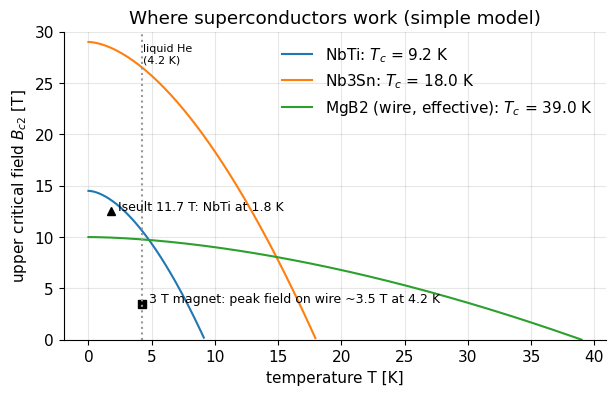

In [4]:
T = np.linspace(0, 40, 400)                               # temperature [K]
mats = {"NbTi": (9.2, 14.5), "Nb3Sn": (18.0, 29.0), "MgB2 (wire, effective)": (39.0, 10.0)}
plt.figure(figsize=(7, 4))
for name, (Tc, Bc0) in mats.items():
    Bc = np.where(T < Tc, Bc0 * (1 - (T / Tc) ** 1.7), np.nan)
    plt.plot(T, Bc, label=f"{name}: $T_c$ = {Tc} K")
plt.plot(4.2, 3.5, "ks"); plt.text(4.8, 3.6, "3 T magnet: peak field on wire ~3.5 T at 4.2 K", fontsize=9)
plt.plot(1.8, 12.5, "k^"); plt.text(2.3, 12.6, "Iseult 11.7 T: NbTi at 1.8 K", fontsize=9)
plt.axvline(4.2, color="0.6", ls=":"); plt.text(4.3, 27, "liquid He\n(4.2 K)", fontsize=8)
plt.xlabel("temperature T [K]"); plt.ylabel("upper critical field $B_{c2}$ [T]"); plt.ylim(0, 30)
plt.title("Where superconductors work (simple model)"); plt.legend()
plt.show()

*Interpretation:* NbTi at 4.2 K has a comfortable margin for 1.5–3 T magnets (the peak field on the conductor is somewhat higher than $B_0$, ~1.2–1.4×). For 7 T and above the margin shrinks, so ultra-high-field magnets operate closer to their limits, use more conductor, or cool to 1.8 K.

> **🔧 Engineering reality:** MRI wire is not a solid superconductor. It consists of tens to thousands of fine NbTi **filaments** (tens of µm) embedded in a **copper matrix**, often soldered into a copper channel (copper:superconductor ratio ~4–10). The copper does nothing while superconducting, but if a spot goes normal it carries the current for a moment and conducts heat away — it is the key to **stability** and **quench protection**. The operating current is chosen at ~70–80 % of the critical current at the peak field ("load-line margin"). NbTi critical current densities are ~3000 A/mm² at 5 T, 4.2 K.

## 3. Designing the coil: amp-turns, homogeneity, forces

### 3.1 Back-of-the-envelope numbers

For a long solenoid $B_0=\mu_0 n I_c$ ([B2](B2_Magnetic_Fields_in_MRI.ipynb)). The total **ampere-turns** needed for a coil of length $L_s$ is

$$NI = n I_c L_s = \frac{B_0 L_s}{\mu_0}$$

*In words:* the product of the number of turns and the current is fixed by the field and the length; the engineer then chooses the current (a few hundred A) and derives the number of turns.
where $NI$ = ampere-turns [A], $B_0$ = field [T], $L_s$ = coil length [m], $\mu_0$ = vacuum permeability.

The field also pushes on the windings with the **magnetic pressure** (= energy density)

$$p_{mag}=\frac{B_0^2}{2\mu_0}$$

*In words:* the field inside tries to expand the solenoid like gas pressure inflates a tyre.
where $p_{mag}$ = pressure [Pa = N/m² = J/m³].

In [5]:
L_s, R_c = 1.6, 0.5                 # coil length and radius [m]
I_op = 500.0                        # operating current [A]
for B0 in [1.5, 3.0, 7.0]:
    NI = B0 * L_s / mt.MU0                         # ampere-turns (ideal long solenoid; real designs need ~1.3-2x more)
    N_turns = NI / I_op
    wire_km = N_turns * 2 * np.pi * R_c / 1e3
    p = B0**2 / (2 * mt.MU0)                       # magnetic pressure [Pa]
    E_bore = p * np.pi * R_c**2 * L_s              # energy stored in the bore volume alone [J]
    print(f"B0 = {B0} T: NI = {NI/1e6:4.1f} MA-turns -> {N_turns:6.0f} turns at {I_op:.0f} A ~ {wire_km:4.0f} km wire; "
          f"pressure = {p/1e6:5.1f} MPa ({p/1.013e5:4.0f} atm); energy in bore volume ~ {E_bore/1e6:4.1f} MJ")

B0 = 1.5 T: NI =  1.9 MA-turns ->   3820 turns at 500 A ~   12 km wire; pressure =   0.9 MPa (   9 atm); energy in bore volume ~  1.1 MJ
B0 = 3.0 T: NI =  3.8 MA-turns ->   7639 turns at 500 A ~   24 km wire; pressure =   3.6 MPa (  35 atm); energy in bore volume ~  4.5 MJ
B0 = 7.0 T: NI =  8.9 MA-turns ->  17825 turns at 500 A ~   56 km wire; pressure =  19.5 MPa ( 192 atm); energy in bore volume ~ 24.5 MJ


*Interpretation:* clinical magnets need millions of ampere-turns and tens of kilometres of superconducting wire. At 3 T the windings feel 36 atmospheres of outward pressure — the coils are wound on precision formers and clamped/epoxy-impregnated, because a wire moving by a few µm releases enough frictional heat to trigger a quench.

### 3.2 A multi-coil magnet design in Python

A single solenoid is hundreds of ppm inhomogeneous over a 50 cm DSV ([B2](B2_Magnetic_Fields_in_MRI.ipynb)). Real magnets use **several coils** whose errors cancel. The idea: on the axis, a symmetric pair of loops at $z=\pm z_k$ contributes

$$B_z(z) = \sum_{n\ \text{even}} c_{n,k}\, z^n$$

*In words:* thanks to the mirror symmetry only even powers of $z$ appear; each coil pair has its own set of coefficients $c_{n,k}$ per unit current.
where $c_{n,k}$ = Taylor coefficient of order $n$ of pair $k$ [T/mⁿ per A-turn].

With $K$ pairs we can choose $K$ currents so that the total field has the right $B_0$ *and* the $z^2, z^4, \dots, z^{2K-2}$ terms vanish — a $K\times K$ linear system. Because $B_z$ satisfies Laplace's equation (see §6), killing the on-axis terms also kills the corresponding off-axis (spherical-harmonic) terms. To evaluate the field off-axis exactly (at the ppm level, which a polygon approximation cannot resolve), we define an exact loop field using elliptic integrals.

In [6]:
from scipy.special import ellipk, ellipe

def loop_field_exact(rho, z, radius, NI=1.0, zc=0.0):
    """Exact field (B_rho, B_z) [T] of a thin circular loop (axis = z, center z=zc) carrying NI ampere-turns.
    Uses complete elliptic integrals K(m), E(m) (scipy convention m = k^2). rho, z in metres (arrays)."""
    z = np.asarray(z, float) - zc
    rho = np.abs(np.asarray(rho, float)) + 1e-12          # avoid division by zero on the axis
    s = (radius + rho) ** 2 + z**2
    m = 4 * radius * rho / s
    K, E = ellipk(m), ellipe(m)
    d = (radius - rho) ** 2 + z**2
    Bz = mt.MU0 * NI / (2 * np.pi * np.sqrt(s)) * (K + (radius**2 - rho**2 - z**2) / d * E)
    Brho = mt.MU0 * NI / (2 * np.pi * rho * np.sqrt(s)) * z * (-K + (radius**2 + rho**2 + z**2) / d * E)
    return Brho, Bz

def magnet_field(rho, z, coils):
    """Total (B_rho, B_z) of symmetric coil pairs; coils = list of (z_k, radius_k, NI_k), each placed at +-z_k."""
    Br, Bz = 0.0, 0.0
    for zk, rk, NIk in coils:
        for sgn in (+1, -1):
            br, bz = loop_field_exact(rho, z, rk, NIk, sgn * zk)
            Br, Bz = Br + br, Bz + bz
    return Br, Bz

# sanity check against mri_tools' numerical Biot-Savart
p = np.array([[0.1, 0.0, 0.2]])
print("exact:", loop_field_exact(0.1, 0.2, 0.5), " mt.loop_coil_field:", mt.loop_coil_field(p, 0.5, 1.0, n_segments=2000)[0, [0, 2]])

exact: (1.08713505102432e-07, 1.0134209904195625e-06)  mt.loop_coil_field: [1.08713909e-07 1.01342253e-06]


Now the design: 6 coil pairs at hand-picked positions on a cylinder of radius 0.5 m, total length 1.6 m. We solve for the ampere-turns that give $B_0$ = 1.5 T and cancel the $z^2\ldots z^{10}$ terms.

In [7]:
def pair_taylor(zk, radius, n_orders, zs=0.05):
    """Even Taylor coefficients (orders 0, 2, 4, ...) of the on-axis field of a loop pair (per A-turn),
    in the scaled variable u = z/zs (numerical polynomial fit around z = 0)."""
    z = np.linspace(-zs, zs, 201)
    b = mt.loop_field_on_axis(z - zk, radius, 1.0) + mt.loop_field_on_axis(z + zk, radius, 1.0)
    return np.polyfit(z / zs, b, 2 * n_orders)[::-1][0:2 * n_orders:2]

def design_magnet(z_pos, radius, B0, extra=None):
    """Solve for NI of each pair so that Bz(0)=B0 and the z^2 ... z^(2K-2) terms vanish.
    extra = optional (z_shield, radius_shield): adds a shield pair and the condition 'total dipole moment = 0'."""
    K = len(z_pos)
    cols = [pair_taylor(zk, radius, K) for zk in z_pos]
    radii = [radius] * K
    if extra is None:
        A = np.array(cols).T
        rhs = np.zeros(K); rhs[0] = B0
    else:
        zsh, rsh = extra
        A = np.array(cols + [pair_taylor(zsh, rsh, K)]).T              # K equations, K+1 unknowns
        A = np.vstack([A, 2 * np.pi * np.array(radii + [rsh]) ** 2])   # + dipole moment sum(NI * pi R^2) * 2 = 0
        rhs = np.zeros(K + 1); rhs[0] = B0
        radii = radii + [rsh]; z_pos = list(z_pos) + [zsh]
    NI = np.linalg.solve(A, rhs)
    return list(zip(z_pos, radii, NI))

B0_design = 1.5
z_pos = [0.05, 0.16, 0.28, 0.42, 0.58, 0.80]
coils_unsh = design_magnet(z_pos, 0.5, B0_design)
for zk, rk, NIk in coils_unsh:
    print(f"pair at z = +-{zk:4.2f} m, R = {rk} m: NI = {NIk/1e3:7.1f} kA-turns each")
print(f"total: {2*sum(abs(c[2]) for c in coils_unsh)/1e6:.2f} MA-turns")

pair at z = +-0.05 m, R = 0.5 m: NI =   129.3 kA-turns each
pair at z = +-0.16 m, R = 0.5 m: NI =   147.8 kA-turns each
pair at z = +-0.28 m, R = 0.5 m: NI =   156.9 kA-turns each
pair at z = +-0.42 m, R = 0.5 m: NI =   211.2 kA-turns each
pair at z = +-0.58 m, R = 0.5 m: NI =   159.0 kA-turns each
pair at z = +-0.80 m, R = 0.5 m: NI =   661.8 kA-turns each
total: 2.93 MA-turns


Evaluate the homogeneity on and inside a 50 cm DSV (in the $x$–$z$ plane; the design is rotationally symmetric about $z$).

DSV 30 cm:    0.02 ppm peak-to-peak
DSV 40 cm:    0.32 ppm peak-to-peak
DSV 45 cm:    1.25 ppm peak-to-peak
DSV 50 cm:    4.36 ppm peak-to-peak


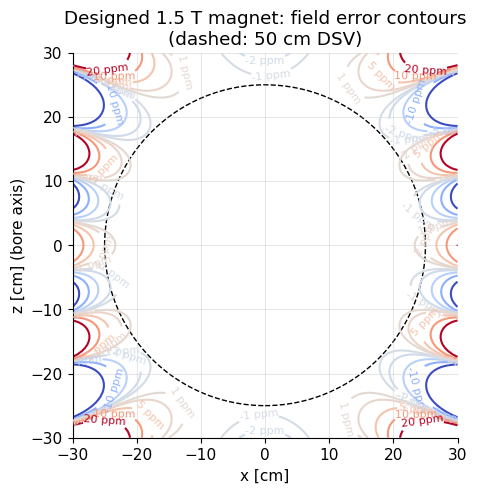

In [8]:
g = np.linspace(-0.3, 0.3, 121)
Xg, Zg = np.meshgrid(g, g)
_, Bz_map = magnet_field(Xg, Zg, coils_unsh)
_, Bc = magnet_field(0.0, 0.0, coils_unsh)
ppm_map = (Bz_map / Bc - 1) * 1e6
th = np.linspace(0, np.pi, 361)
for dsv in [0.30, 0.40, 0.45, 0.50]:
    _, b = magnet_field(dsv / 2 * np.sin(th), dsv / 2 * np.cos(th), coils_unsh)
    print(f"DSV {dsv*100:2.0f} cm: {(b.max()-b.min())/Bc*1e6:7.2f} ppm peak-to-peak")
plt.figure(figsize=(6, 5))
lev = [-20, -10, -5, -2, -1, 1, 2, 5, 10, 20]
cs = plt.contour(Xg * 100, Zg * 100, ppm_map, levels=lev, cmap="coolwarm")
plt.clabel(cs, fmt="%g ppm", fontsize=8)
plt.gca().add_patch(plt.Circle((0, 0), 25, fill=False, ls="--", color="k"))
plt.xlabel("x [cm]"); plt.ylabel("z [cm] (bore axis)"); plt.gca().set_aspect("equal")
plt.title(f"Designed {B0_design} T magnet: field error contours\n(dashed: 50 cm DSV)")
plt.show()

*Interpretation:* six coil pairs (12 coils) bring a 1.6 m long magnet to a few ppm over a 50 cm sphere — compare with ~38 000 ppm for a single 1.5 m solenoid. Outside the DSV the error grows rapidly (like $r^{12}$, the first non-cancelled order). Real manufacturing tolerances (a coil displaced by 0.1 mm!) add hundreds of ppm of error, which is removed by **shimming** (§7).

## 4. Persistent mode, stored energy and drift

### 4.1 Persistent mode
The magnet is **ramped** once: a power supply drives current into the coil while a short piece of superconductor connecting the coil ends — the **persistent switch** — is kept warm (normal-conducting) by a small heater. When the target current is reached, the heater is switched off, the switch becomes superconducting, and the current circulates in a closed superconducting loop. The power supply is ramped down and disconnected. The magnet now runs for years without power.

Ramping is slow because the coil is a huge inductor: the voltage across it is $V=L\,dI_c/dt$; with $L\approx 30$ H and a few volts allowed, $dI_c/dt\approx0.1$ A/s, so reaching 400–500 A takes about an hour or more.

### 4.2 Stored energy and inductance
The energy stored in the field is

$$E_{mag} = \tfrac12 L I_c^2 = \int \frac{B^2}{2\mu_0}\,dV$$

*In words:* the energy can be seen either as "inductance × current²/2" (circuit view) or as energy density $B^2/2\mu_0$ integrated over all space (field view).
where $E_{mag}$ = stored energy [J], $L$ = inductance [H], $I_c$ = current [A], $B$ = field magnitude [T], $V$ = volume [m³].

For our coil set we compute it in the circuit view, $E_{mag}=\frac12\sum_{i,j}(NI)_i(NI)_j M_{ij}$, with the **mutual inductances** $M_{ij}$ between coaxial loops (elliptic-integral formula) and the self-inductance of a loop with a winding bundle of radius $a$, $L_{self}=\mu_0R_c[\ln(8R_c/a)-1.75]$.

In [9]:
def mutual_inductance(R1, R2, d):
    """Mutual inductance [H] of two coaxial thin loops (radii R1, R2, axial distance d)."""
    k2 = 4 * R1 * R2 / ((R1 + R2) ** 2 + d**2); k = np.sqrt(k2)
    return mt.MU0 * np.sqrt(R1 * R2) * ((2 / k - k) * ellipk(k2) - 2 / k * ellipe(k2))

def stored_energy(coils, a_bundle=0.03):
    """Magnetic energy [J] of symmetric coil pairs, each coil a single 'turn' carrying NI (bundle radius a)."""
    loops = [(s * zk, rk, NIk) for zk, rk, NIk in coils for s in (+1, -1)]
    E = 0.0
    for i, (zi, ri, Ii) in enumerate(loops):
        for j, (zj, rj, Ij) in enumerate(loops):
            M = mt.MU0 * ri * (np.log(8 * ri / a_bundle) - 1.75) if i == j else mutual_inductance(ri, rj, zi - zj)
            E += 0.5 * Ii * Ij * M
    return E

E15 = stored_energy(coils_unsh)
print(f"Our unshielded {B0_design} T design stores E = {E15/1e6:.1f} MJ")
for I_op in [300.0, 500.0, 700.0]:
    print(f"  operated at {I_op:.0f} A -> inductance L = 2E/I^2 = {2*E15/I_op**2:5.1f} H")
print(f"Scaling the same geometry to 3 T (E ~ B0^2): {E15*(3/1.5)**2/1e6:.0f} MJ;  to 7 T: {E15*(7/1.5)**2/1e6:.0f} MJ")
print(f"For comparison: 10 MJ = a 1-tonne car lifted {10e6/(1000*9.81):.0f} m, or ~{10e6/4.2e6:.1f} kg of TNT")

Our unshielded 1.5 T design stores E = 2.0 MJ
  operated at 300 A -> inductance L = 2E/I^2 =  44.7 H
  operated at 500 A -> inductance L = 2E/I^2 =  16.1 H
  operated at 700 A -> inductance L = 2E/I^2 =   8.2 H
Scaling the same geometry to 3 T (E ~ B0^2): 8 MJ;  to 7 T: 44 MJ
For comparison: 10 MJ = a 1-tonne car lifted 1019 m, or ~2.4 kg of TNT


*Interpretation:* an unshielded 1.5 T magnet stores ~2 MJ; active shielding (§8) roughly doubles it, so real clinical magnets store a few MJ at 1.5 T and ~10–15 MJ at 3 T. Whole-body 7 T magnets store tens of MJ, and Iseult's 11.7 T magnet ~340 MJ. All of this energy is released within seconds to a minute if the magnet quenches (§5).

### 4.3 Field drift: how good is "zero resistance"?
In persistent mode the circuit is an inductor $L$ shorted by a tiny residual resistance $R_{el}$ (mostly the superconducting joints and the switch). The current decays exponentially:

$$I_c(t) = I_c(0)\,e^{-t/\tau},\qquad \tau = \frac{L}{R_{el}}$$

*In words:* an L–R circuit loses current with time constant $L/R_{el}$ (first-order ODE, [refresher](../refreshers/RM1_ODEs_for_MRI.ipynb)); for small times the relative drift per unit time is $1/\tau = R_{el}/L$.
where $\tau$ = time constant [s], $R_{el}$ = residual resistance [Ω].

Magnet specs require a drift below ~0.1 ppm per hour. What resistance does that allow?

In [10]:
L_mag = 30.0                                         # typical inductance [H]
drift = 0.1e-6 / 3600                                # 0.1 ppm per hour, in 1/s
R_max = drift * L_mag
tau_years = 1 / drift / (3600 * 24 * 365)
print(f"allowed residual resistance: {R_max*1e9:.2f} nOhm; time constant tau = {tau_years:.0f} years")
f0 = mt.larmor_frequency(1.5)
print(f"0.1 ppm/h at 1.5 T = {0.1e-6*f0:.1f} Hz per hour -> {0.1e-6*f0*24:.0f} Hz per day of center-frequency drift")

allowed residual resistance: 0.83 nOhm; time constant tau = 1142 years
0.1 ppm/h at 1.5 T = 6.4 Hz per hour -> 153 Hz per day of center-frequency drift


*Interpretation:* the joints must have below ~1 nΩ — achievable only with superconducting joints (crimped/cold-pressed NbTi filaments). A drift of 6 Hz/h is still enough that the scanner re-measures the center frequency at every prescan ([B1](B1_MRI_System.ipynb)), and the magnet is occasionally re-energized ("topped up") over its lifetime.

## 5. Cryostat, liquid helium and cryocoolers

The coil must be kept at ~4 K inside a room-temperature machine with a 60–70 cm warm bore. The **cryostat** is a giant thermos flask:

* the **helium vessel** containing the coil immersed in liquid helium (LHe; boils at 4.2 K at 1 atm);
* one or two **thermal radiation shields** (~40–50 K and ~10–20 K) wrapped in **multi-layer insulation** (aluminized Mylar "super-insulation");
* an outer **vacuum vessel**; the vacuum eliminates heat conduction and convection by gas;
* low-conductivity **supports** (fibreglass straps) holding the multi-tonne cold mass against magnetic and gravitational forces;
* a **cold head** (2-stage Gifford–McMahon or pulse-tube cryocooler): the first stage cools the shield (~40 K, tens of W), the second stage (~4 K, ~1–1.5 W) **re-condenses** evaporated helium back into the vessel. It is driven by a helium compressor (~7–10 kW electric, water cooled).

A conventional 1.5–3 T magnet holds ~1500–2000 L of LHe. How much boils off for a given heat leak $\dot Q$?

$$\dot V_{LHe} = \frac{\dot Q}{\rho_{He}\,h_{fg}}$$

*In words:* each watt of heat reaching the bath evaporates a fixed volume of liquid per second, set by the latent heat per litre.
where $\dot V_{LHe}$ = liquid evaporation rate [m³/s], $\dot Q$ = heat leak [W], $\rho_{He}$ = 125 kg/m³, $h_{fg}$ = 20.9 kJ/kg.

In [11]:
rho_He, h_fg = 125.0, 20.9e3               # LHe density [kg/m^3], latent heat [J/kg]
J_per_L = rho_He * 1e-3 * h_fg             # energy to evaporate 1 litre [J/L]
print(f"Evaporating 1 L of LHe needs only {J_per_L/1e3:.1f} kJ (water: ~2260 kJ)")
for Q in [0.1, 0.5, 1.0]:
    L_per_h = Q * 3600 / J_per_L
    print(f"heat leak {Q:3.1f} W -> {L_per_h:4.2f} L/h = {L_per_h*24:5.1f} L/day; 1500 L lasts {1500/(L_per_h*24):5.0f} days")
# helium gas volume from liquid (ideal gas at 20 C, 1 atm)
n_mol_per_L = rho_He * 1e-3 / 4.0026e-3                        # mol per litre of liquid
gas_L = n_mol_per_L * 8.314 * 293.15 / 101325 * 1e3            # litres of gas per litre of liquid
print(f"1 L of liquid helium -> {gas_L:.0f} L of gas at room temperature")

Evaporating 1 L of LHe needs only 2.6 kJ (water: ~2260 kJ)
heat leak 0.1 W -> 0.14 L/h =   3.3 L/day; 1500 L lasts   454 days
heat leak 0.5 W -> 0.69 L/h =  16.5 L/day; 1500 L lasts    91 days
heat leak 1.0 W -> 1.38 L/h =  33.1 L/day; 1500 L lasts    45 days
1 L of liquid helium -> 751 L of gas at room temperature


*Interpretation:* liquid helium has a tiny latent heat, so even 1 W of heat leak boils ~1.4 L per hour. Before cryocoolers, magnets needed refills every few weeks to months. With a working 4 K cold head modern magnets are "**zero boil-off**": the cold head re-condenses everything. If the cold head or compressor fails (power cut, cooling-water failure), the helium level starts dropping and the service team has days to weeks to fix it before the magnet risks a quench.

> **🔧 Engineering reality — the helium problem and sealed magnets:** helium is a non-renewable by-product of natural-gas extraction, with volatile price and recurring shortages. Vendors have responded with **sealed, low-helium** magnets: e.g. Philips "BlueSeal" 1.5 T (~7 L of LHe, sealed for life, no quench pipe needed) and Siemens "DryCool" magnets (e.g. the 0.55 T MAGNETOM Free.Max, < 1 L), where the coil is cooled by conduction or a small closed helium circuit attached to the cold head rather than immersion in a bath. The trade-off: less thermal buffer, so a cooling outage warms the coil faster, and ramp-up after an outage is needed more often.

## 6. Quench

A **quench** is the sudden loss of superconductivity in the magnet. It can start from a tiny disturbance (a wire moving by micrometres, an epoxy crack, insufficient helium so the coil top is uncovered), or be triggered deliberately with the **emergency run-down / quench button** (e.g. to free a person pinned by a ferromagnetic object — the field cannot be switched off any other way).

What happens:
1. A small **normal zone** appears; there the current flows through the copper matrix and generates heat $I_c^2R_{el}$.
2. The heat spreads, the normal zone grows (centimetres to metres per second), and its resistance $R_{el}(t)$ rises.
3. The current decays as the inductor discharges into the growing resistance: $L\,dI_c/dt=-R_{el}(t)\,I_c$. The full stored energy (MJ!) ends up as heat in the cold mass.
4. The heat boils the liquid helium violently; the gas (≈750× the liquid volume) leaves through burst discs into the **quench vent pipe** to the outside.

**Protection:** if the energy were deposited in a small normal zone, it would melt the wire. Magnets are therefore divided into sections with **cold diodes/resistors** across them, and **quench heaters** deliberately drive the whole winding normal within ~1 s so the energy is spread over the entire cold mass (hundreds of kg to tonnes). The field decays within ~10–60 s.

A simple model (first-order ODE with a time-varying coefficient, solved by numerical stepping): $R_{el}(t)$ grows like $t^3$ (a 3D normal zone expanding at constant speed) until the protection heaters make the whole coil resistive.

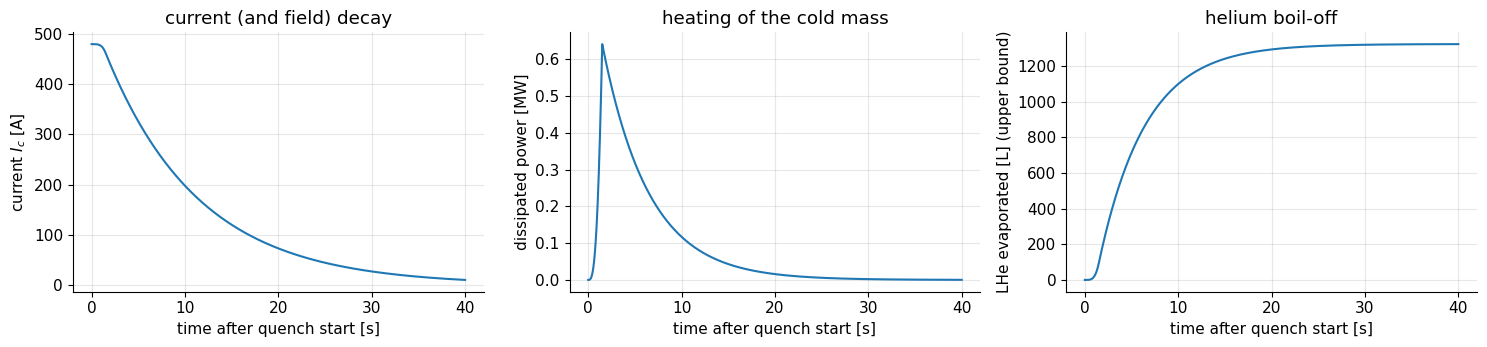

stored energy 3.5 MJ; peak power 0.64 MW; field at 10 % after 24 s
if all energy evaporated helium: 1322 L  -> 993 m^3 of gas


In [12]:
L_mag, I0 = 30.0, 480.0                   # inductance [H], operating current [A]  (E = 1/2 L I^2 ~ 3.5 MJ)
R_full, t_full = 3.0, 1.5                 # resistance of the fully normal coil [ohm]; time to get there [s]
dt = 1e-3
t = np.arange(0, 40, dt)
R_t = R_full * np.minimum(1.0, (t / t_full) ** 3)       # normal-zone resistance [ohm]
I = np.empty_like(t); I[0] = I0
for k in range(len(t) - 1):                              # explicit Euler step of L dI/dt = -R I
    I[k + 1] = I[k] - dt * R_t[k] * I[k] / L_mag
E = 0.5 * L_mag * I**2                                   # remaining stored energy [J]
P = R_t * I**2                                           # power dissipated in the coil [W]
boiled_L = (E[0] - E) / J_per_L                          # LHe evaporated if ALL heat went into the helium [L]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(t, I); ax[0].set_ylabel("current $I_c$ [A]"); ax[0].set_title("current (and field) decay")
ax[1].plot(t, P / 1e6); ax[1].set_ylabel("dissipated power [MW]"); ax[1].set_title("heating of the cold mass")
ax[2].plot(t, boiled_L); ax[2].set_ylabel("LHe evaporated [L] (upper bound)"); ax[2].set_title("helium boil-off")
for a in ax: a.set_xlabel("time after quench start [s]")
plt.tight_layout(); plt.show()
print(f"stored energy {E[0]/1e6:.1f} MJ; peak power {P.max()/1e6:.2f} MW; field at 10 % after {t[np.argmax(I < 0.1*I0)]:.0f} s")
print(f"if all energy evaporated helium: {boiled_L[-1]:.0f} L  -> {boiled_L[-1]*gas_L/1e3:.0f} m^3 of gas")

*Interpretation:* the field collapses within tens of seconds, the coil absorbs megawatts of heating, and in the extreme case the deposited energy is enough to evaporate the entire helium inventory, i.e. **~1000 m³ of cold helium gas** in a minute. (Part of the energy actually warms the cold mass instead, but large losses — often most of the helium — are typical.) After a quench the magnet must be cooled, refilled and re-ramped: days of downtime and a large helium bill.

**Why the quench pipe and O₂ monitor matter:** if the vent pipe fails and the gas enters the magnet room, it displaces the air:

In [13]:
room = 7 * 5 * 3.0                          # magnet room volume [m^3]
for frac_into_room in [0.05, 0.2, 0.5]:
    V_He = frac_into_room * 1500 * gas_L / 1e3                 # m^3 of He gas entering the room
    # fully mixed and vented to keep pressure: O2 fraction drops as fresh volume is replaced
    O2 = 20.9 * np.exp(-V_He / room)
    print(f"{frac_into_room*100:3.0f} % of 1500 L LHe into a {room:.0f} m^3 room: {V_He:6.0f} m^3 gas -> O2 ~ {O2:4.1f} %")

  5 % of 1500 L LHe into a 105 m^3 room:     56 m^3 gas -> O2 ~ 12.2 %
 20 % of 1500 L LHe into a 105 m^3 room:    225 m^3 gas -> O2 ~  2.4 %
 50 % of 1500 L LHe into a 105 m^3 room:    563 m^3 gas -> O2 ~  0.1 %


*Interpretation:* even a small fraction of the gas would lower the oxygen concentration below the ~19.5 % safety threshold, and larger amounts are lethal (asphyxiation, without warning — helium is odourless). In addition the gas is extremely cold (frostbite) and the room may be pressurized, making the door hard to open (rooms have pressure-relief vents). Hence: a properly dimensioned, regularly inspected quench pipe, O₂ sensors in the magnet room, and training. → [B6 MRI Safety](B6_MRI_Safety.ipynb)

> **⚠️ Common confusion:** "turning off the magnet" is not a switch-off: it is either a controlled **ramp-down** by a service engineer (hours, helium kept) or an emergency **quench** (seconds, helium lost). The magnet is on even when the scanner is "off".

## 7. Homogeneity: spherical harmonics

### 7.1 Why spherical harmonics?
Inside the bore there are no currents, so each Cartesian component of $\vec B$, in particular $B_z$, satisfies **Laplace's equation** $\nabla^2 B_z = 0$ (it follows from $\nabla\cdot\vec B=0$ and $\nabla\times\vec B=0$). The natural building blocks for solutions of Laplace's equation inside a sphere are the **solid spherical harmonics**:

$$B_z(r,\theta,\varphi) = \sum_{n=0}^{\infty}\sum_{m=0}^{n}\left(\frac{r}{r_0}\right)^n P_n^m(\cos\theta)\,\big[A_{nm}\cos m\varphi + B_{nm}\sin m\varphi\big]$$

*In words:* any field error inside the DSV can be written as a sum of standard "shapes" of increasing complexity; the degree $n$ tells how fast a term grows with radius ($r^n$), the order $m$ how many times it oscillates around the $z$-axis.
where $r,\theta,\varphi$ = spherical coordinates (radius, polar angle from the $z$-axis, azimuth) [m, rad], $r_0$ = reference radius (DSV radius) [m], $P_n^m$ = associated Legendre function, $A_{nm},B_{nm}$ = coefficients [T] (the field contribution of each term at $r=r_0$). Terms with $m=0$ are axially symmetric (**zonal**), $m>0$ are **tesseral**.

Low orders written in Cartesian coordinates (up to constant factors) — these are the names on shim-coil channels:

| $n$ | $m=0$ | $m=1$ | $m=2$ | $m=3$ |
|---|---|---|---|---|
| 0 | 1 (= $B_0$ offset, set by the frequency) | | | |
| 1 | $z$ (= $G_z$) | $x$, $y$ (= $G_x, G_y$) | | |
| 2 | $z^2-\frac12(x^2+y^2)$ ("Z2") | $zx$, $zy$ | $x^2-y^2$, $xy$ | |
| 3 | $z^3-\frac32 z(x^2+y^2)$ ("Z3") | $x(4z^2-x^2-y^2)$, $y(\dots)$ | $z(x^2-y^2)$, $zxy$ | $x^3-3xy^2$, $3x^2y-y^3$ |

Two practical consequences:
* A **harmonic function attains its maximum and minimum on the boundary** of the region. So the peak-to-peak homogeneity of a DSV is fully determined by the field on its **surface**: magnet field mapping is done by rotating a probe (an NMR probe or a phantom) over the surface of the DSV sphere.
* Higher orders grow faster with radius ($r^n$): an error that is small at 20 cm can be large at 25 cm. This is why the specification always names the DSV: e.g. "< 1 ppm over 30 cm, < 4 ppm over 50 cm".

Specifications are given as **peak-to-peak** (pk-pk) or **volume-RMS** (V-rms) ppm over a DSV, typically for clinical whole-body magnets: ~0.5–1 ppm V-rms / a few ppm pk-pk over 40–50 cm after shimming.

The next cell defines a real spherical-harmonic basis and decomposes the field of our designed magnet (which only has zonal $m=0$ terms by symmetry).

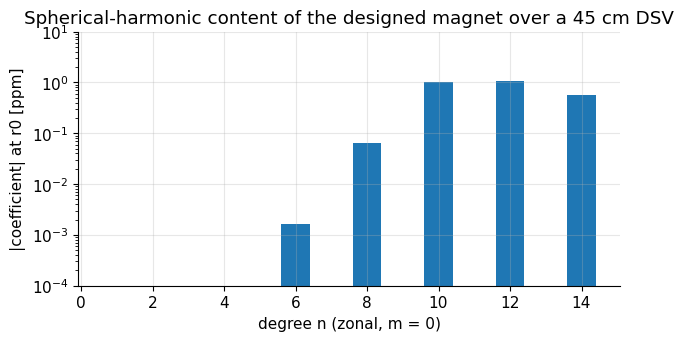

pk-pk over the 45 cm DSV surface: 1.25 ppm


In [14]:
from scipy.special import lpmv

def sph_basis(xyz, n_max, r0):
    """Real solid spherical harmonics (r/r0)^n P_n^m(cos th) {cos m phi, sin m phi} for 0<=n<=n_max.
    Returns (matrix of shape (Npoints, Nterms), list of (n, m, 'c'/'s') labels)."""
    x, y, z = xyz[:, 0], xyz[:, 1], xyz[:, 2]
    r = np.sqrt(x**2 + y**2 + z**2); r_safe = np.where(r == 0, 1e-12, r)
    cth = z / r_safe; ph = np.arctan2(y, x)
    cols, labels = [], []
    for n in range(n_max + 1):
        for m in range(n + 1):
            base = (r / r0) ** n * lpmv(m, n, cth)
            base = base / max(1.0, np.max(np.abs(lpmv(m, n, np.linspace(-1, 1, 201)))))  # O(1) scale at r0
            cols.append(base * np.cos(m * ph)); labels.append((n, m, "c"))
            if m > 0:
                cols.append(base * np.sin(m * ph)); labels.append((n, m, "s"))
    return np.array(cols).T, labels

def sphere_points(n_pts, radius):
    """Quasi-uniform points on a sphere (Fibonacci lattice)."""
    i = np.arange(n_pts) + 0.5
    th = np.arccos(1 - 2 * i / n_pts); ph = np.pi * (1 + 5**0.5) * i
    return radius * np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)], -1)

r0 = 0.225                                     # 45 cm DSV
pts_dsv = sphere_points(1000, r0)
rho_p = np.hypot(pts_dsv[:, 0], pts_dsv[:, 1])
_, Bz_design = magnet_field(rho_p, pts_dsv[:, 2], coils_unsh)
ppm_design = (Bz_design / Bc - 1) * 1e6
A, labels = sph_basis(pts_dsv, 14, r0)
coef, *_ = np.linalg.lstsq(A, ppm_design, rcond=None)
zonal = [(lab[0], c) for lab, c in zip(labels, coef) if lab[1] == 0 and lab[0] > 0]
plt.figure(figsize=(7, 3.3))
plt.bar([n for n, _ in zonal], [abs(c) for _, c in zonal])
plt.yscale("log"); plt.ylim(1e-4, 10); plt.xlabel("degree n (zonal, m = 0)"); plt.ylabel("|coefficient| at r0 [ppm]")
plt.title("Spherical-harmonic content of the designed magnet over a 45 cm DSV")
plt.show()
print(f"pk-pk over the 45 cm DSV surface: {ppm_design.max()-ppm_design.min():.2f} ppm")

*Interpretation:* odd orders vanish (mirror symmetry) and $n$ = 2…10 are suppressed to numerical noise by the design; what remains is dominated by $n=12$, the first order that 6 pairs cannot cancel. A magnet designer's job is exactly this: push the first uncancelled order high enough that its $r^n$ growth stays small inside the DSV.

## 8. Shimming

Shimming removes the field errors left after manufacturing (hundreds of ppm), the influence of the site (steel in the building), and the patient's own susceptibility distortions.

| Shim type | What | When | Orders |
|---|---|---|---|
| **Superconducting shims** | extra superconducting coils in the cryostat | set at installation | low orders (1–3) |
| **Passive shims** | small steel pieces (sheets, "coins") in pockets of shim trays inside the bore | at installation (iterative: map → compute → insert → re-map) | effectively all orders |
| **Active (resistive) shims** | room-temperature coils; 1st order = DC offsets on the gradient coils, 2nd (and sometimes 3rd) order = dedicated coils | every patient / series ("prescan") | 1st–2nd (3rd) |
| Dynamic / local shims | shim updates per slice, or multi-coil shim arrays near the head | research / advanced | |

### 8.1 Passive shimming with iron pieces (simulation)
A piece of steel in a strong field is **saturated**: it becomes a magnetic dipole of moment $m=M_sV$ pointing along $z$, where $M_s$ is the saturation magnetization and $V$ the steel volume. Its field at relative position $\vec d$ (distance $d$, angle $\alpha$ to the $z$-axis) is

$$\Delta B_z = \frac{\mu_0\,m}{4\pi\,d^3}\,(3\cos^2\alpha-1)$$

*In words:* a dipole field: positive "above and below" the iron piece (along $z$), negative "beside" it, falling off like $1/d^3$.
where $\Delta B_z$ [T], $m$ = dipole moment [A m²], $d$ = distance [m], $\alpha$ = angle between $\vec d$ and $z$.

Because the field is linear in the iron volumes, shimming is a linear least-squares problem — with the constraint that you can only **add** iron (volume ≥ 0, and ≤ the pocket size). We simulate: 24 shim trays around the bore at radius 0.32 m, 16 pockets each, and a 1.5 T magnet whose field contains the design residual plus random "manufacturing" errors of a few hundred ppm.

before passive shimming:  177.4 ppm pk-pk,  34.9 ppm rms
after  passive shimming:   26.8 ppm pk-pk,  3.52 ppm rms
steel used: 563 cm^3 = 4.43 kg in 250 of 384 pockets


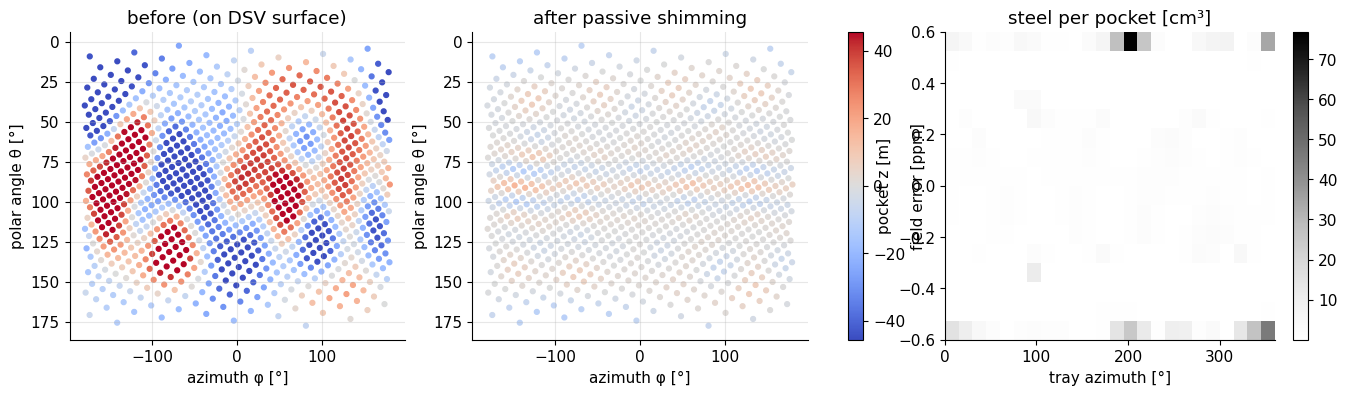

In [15]:
from scipy.optimize import lsq_linear

rng = np.random.default_rng(7)
B0 = B0_design
# (a) "measured" field on the 45 cm DSV surface: design residual + random manufacturing errors (orders 1-6)
A6, lab6 = sph_basis(pts_dsv, 6, r0)
err_coef = np.array([rng.normal(0, 60.0 / (1 + n) ) if n > 0 else 0.0 for (n, m, cs) in lab6])   # [ppm at r0]
dB_manuf = A6 @ err_coef                                   # [ppm]
dB_meas = ppm_design + dB_manuf                            # total field error before shimming [ppm]

# (b) shim pockets: 24 trays x 16 axial positions on a cylinder of radius 0.32 m
Ms = 1.7e6                                                 # saturation magnetization of steel [A/m]
phi_t = 2 * np.pi * np.arange(24) / 24
z_t = np.linspace(-0.6, 0.6, 16)
N_TRAYS, N_POCK = 24, 16
PH, ZT = np.meshgrid(phi_t, z_t)
pockets = np.stack([0.32 * np.cos(PH).ravel(), 0.32 * np.sin(PH).ravel(), ZT.ravel()], -1)

def dipole_bz_ppm(points, sources, B0):
    """Bz [ppm of B0] at `points` per cm^3 of saturated steel at each source: matrix (Npoints, Nsources)."""
    d = points[:, None, :] - sources[None, :, :]
    dn = np.linalg.norm(d, axis=-1)
    cos_a = d[..., 2] / dn
    m = Ms * 1e-6                                         # dipole moment of 1 cm^3 [A m^2]
    return mt.MU0 * m / (4 * np.pi * dn**3) * (3 * cos_a**2 - 1) / B0 * 1e6

S = dipole_bz_ppm(pts_dsv, pockets, B0)                    # (1000, 384)
# unknowns: steel volume in each pocket [cm^3] (0..100) + one free constant (the mean field shift)
Afull = np.hstack([S, np.ones((len(pts_dsv), 1))])
lb = np.r_[np.zeros(S.shape[1]), -np.inf]; ub = np.r_[np.full(S.shape[1], 100.0), np.inf]   # up to 100 cm^3 per pocket
res = lsq_linear(Afull, -dB_meas, bounds=(lb, ub))
vol = res.x[:-1]
dB_after = dB_meas + S @ vol
dB_after -= dB_after.mean()
print(f"before passive shimming: {np.ptp(dB_meas):6.1f} ppm pk-pk, {np.std(dB_meas):5.1f} ppm rms")
print(f"after  passive shimming: {np.ptp(dB_after):6.1f} ppm pk-pk, {np.std(dB_after):5.2f} ppm rms")
print(f"steel used: {vol.sum():.0f} cm^3 = {vol.sum()*7.87e-3:.2f} kg in {np.sum(vol > 0.05)} of {len(vol)} pockets")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
th_p = np.degrees(np.arccos(pts_dsv[:, 2] / r0)); ph_p = np.degrees(np.arctan2(pts_dsv[:, 1], pts_dsv[:, 0]))
vmax = np.abs(dB_meas).max()
for a_, data, ttl in [(ax[0], dB_meas - dB_meas.mean(), "before (on DSV surface)"), (ax[1], dB_after, "after passive shimming")]:
    sc = a_.scatter(ph_p, th_p, c=data, cmap="coolwarm", vmin=-vmax / 2, vmax=vmax / 2, s=12)
    a_.set_xlabel("azimuth φ [°]"); a_.set_ylabel("polar angle θ [°]"); a_.set_title(ttl); a_.invert_yaxis()
plt.colorbar(sc, ax=ax[:2], label="field error [ppm]", fraction=0.03)
im = ax[2].imshow(vol.reshape(16, 24), aspect="auto", cmap="Greys", extent=[0, 360, -0.6, 0.6], origin="lower")
ax[2].set_xlabel("tray azimuth [°]"); ax[2].set_ylabel("pocket z [m]"); ax[2].set_title("steel per pocket [cm³]"); ax[2].grid(False)
plt.colorbar(im, ax=ax[2], fraction=0.046)
plt.show()

*Interpretation:* a few kilograms of carefully placed steel reduce a ~180 ppm error about 7-fold in pk-pk (~10-fold in rms) over the 45 cm DSV. What remains is high-order detail that our coarse 24 × 16 pocket grid cannot represent; real shim sets (finer pocket grids, several iterations, combined with superconducting shims) reach a few ppm.

> **TODO (polish):** tune the passive-shim simulation (finer pocket grid / LP minimizing pk-pk) so it reaches the few-ppm level of real magnets. Real shim software solves the same linear problem, usually with linear programming to minimize the *peak-to-peak* error or the steel mass; the process is iterated 2–4 times because placement is imperfect.

> **🔧 Engineering reality:** passive shims sit close to the gradient coil, which heats up during demanding scans (EPI, diffusion). Steel magnetization changes with temperature, so the shim field — and $B_0$ — drifts by fractions of a ppm during a long scan. Vendors cool the shim trays and the sequences track the frequency.

### 8.2 Patient-specific active shimming
Even a perfect magnet is distorted by the patient: tissue (water, $\chi\approx-9\times10^{-6}$) and air ($\chi\approx+0.4\times10^{-6}$) have different susceptibilities, so air cavities (sinuses, ear canals, lungs, bowel gas) create local field errors of several ppm. At each prescan the scanner measures a **$B_0$ field map** (two gradient echoes with different TE: $\Delta B_0 = \Delta\phi/(\gamma\,\Delta TE)$) in the region of interest and solves a least-squares problem for the shim currents.

Our model "head": a water sphere (radius 9 cm) with an air-filled "sinus" (radius 1.8 cm, anterior–inferior) and two small "ear canals". An air sphere of radius $a$ in water perturbs the field outside it like a dipole:

$$\Delta B_z = \frac{\Delta\chi}{3}B_0\frac{a^3}{d^3}(3\cos^2\alpha-1),\qquad \Delta\chi=\chi_{air}-\chi_{water}\approx 9.4\times10^{-6}$$

*In words:* the cavity acts like a small magnet; the field is up to $\frac23\Delta\chi\approx 6$ ppm at its "poles" and decays like $1/d^3$.
where $a$ = cavity radius [m], $d$ = distance from its center [m], $\alpha$ = angle to $z$.
We add a slowly varying body/shoulder field (a few ppm in 1st/2nd order) and the residual magnet error from §8.1, then shim with 1st, 2nd and 3rd order.

shim order 0: residual 1.27 ppm rms (162.6 Hz at 3.0 T),   6.3 ppm pk-pk
shim order 1: residual 0.48 ppm rms ( 61.5 Hz at 3.0 T),   5.8 ppm pk-pk
shim order 2: residual 0.21 ppm rms ( 27.4 Hz at 3.0 T),   5.2 ppm pk-pk
shim order 3: residual 0.21 ppm rms ( 26.7 Hz at 3.0 T),   5.2 ppm pk-pk


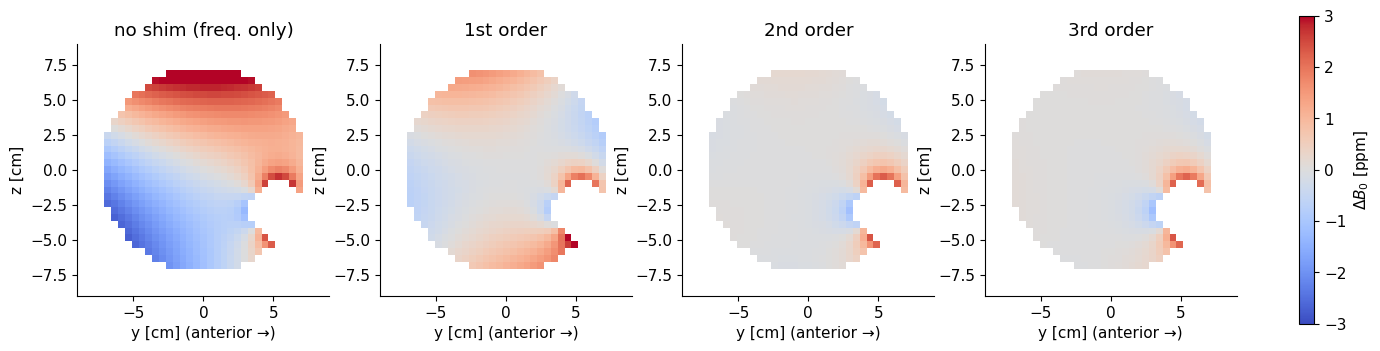

In [16]:
B0 = 3.0
dchi = 0.36e-6 - (-9.05e-6)                                 # air - water
cavities = [((0.0, 0.055, -0.03), 0.018), ((0.065, 0.0, -0.035), 0.008), ((-0.065, 0.0, -0.035), 0.008)]
g = np.linspace(-0.09, 0.09, 37)
Xh, Yh, Zh = np.meshgrid(g, g, g, indexing="ij")
P = np.stack([Xh.ravel(), Yh.ravel(), Zh.ravel()], -1)
brain = np.linalg.norm(P, axis=1) < 0.075                   # region of interest (inside the head)
dB = np.zeros(len(P))                                       # field error [ppm]
for c, a in cavities:
    d = P - np.array(c); dn = np.linalg.norm(d, axis=1)
    out = dn > a
    dB[out] += dchi / 3 * (a / dn[out]) ** 3 * (3 * (d[out, 2] / dn[out]) ** 2 - 1) * 1e6
    brain &= dn > a + 0.003                                  # no signal inside the air cavities
# smooth body/shoulder contribution + residual of the (passively shimmed) magnet [ppm]
A3, lab3 = sph_basis(P, 3, 0.1)
body_coef = np.zeros(len(lab3))
for (n, m, cs), val in {(1, 0, "c"): 3.0, (1, 1, "s"): -1.5, (2, 0, "c"): 2.4, (2, 1, "s"): 1.2, (3, 0, "c"): 0.6}.items():
    body_coef[lab3.index((n, m, cs))] = val
dB += A3 @ body_coef

results = {}
for order in [0, 1, 2, 3]:
    Ab, _ = sph_basis(P[brain], order, 0.1)                  # order 0 = frequency adjustment only
    cf, *_ = np.linalg.lstsq(Ab, dB[brain], rcond=None)
    resid = dB.copy(); resid[brain] -= Ab @ cf
    results[order] = resid
    print(f"shim order {order}: residual {np.std(resid[brain]):4.2f} ppm rms "
          f"({np.std(resid[brain])*mt.larmor_frequency(B0)*1e-6:5.1f} Hz at {B0} T), {np.ptp(resid[brain]):5.1f} ppm pk-pk")

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ix = np.argmin(np.abs(g - 0.0))                             # sagittal slice x = 0
for a_, order in zip(ax, [0, 1, 2, 3]):
    vol_ = np.where(brain, results[order], np.nan).reshape(Xh.shape)
    im = a_.imshow(vol_[ix].T, origin="lower", cmap="coolwarm", vmin=-3, vmax=3,
                   extent=[g[0]*100, g[-1]*100, g[0]*100, g[-1]*100])
    a_.set_title(["no shim (freq. only)", "1st order", "2nd order", "3rd order"][order]); a_.grid(False)
    a_.set_xlabel("y [cm] (anterior →)"); a_.set_ylabel("z [cm]")
plt.colorbar(im, ax=ax, fraction=0.015, label="$\\Delta B_0$ [ppm]")
plt.show()

*Interpretation:* low-order shims remove the smooth, large-scale part of the error (body, magnet residual) very effectively, but the sharp, local field around the "sinus" (bottom-front of each panel) cannot be represented by a few low-order harmonics — the residual stays at several ppm there. This is exactly where real brain images show signal dropouts and distortion (orbitofrontal cortex, temporal lobes near the ear canals), and why higher-order or local multi-coil shim arrays are a research topic.

## 9. Active shielding and the fringe field

Far away, any magnet looks like a **magnetic dipole** whose field decays as $1/r^3$:

$$|\vec B(r,\theta)| \approx \frac{\mu_0\,m}{4\pi r^3}\sqrt{1+3\cos^2\theta},\qquad m=\sum_k (NI)_k\,\pi R_k^2$$

*In words:* the stray field falls off with the cube of distance and is twice as strong along the axis ($\theta=0$) as at the same distance sideways; its strength is set by the total "ampere-turns × area" of the coils (the dipole moment).
where $m$ = dipole moment [A m²], $r$ = distance from the magnet center [m], $\theta$ = angle from the bore axis.

The **5-gauss line** (0.5 mT) is the internationally used boundary beyond which the fringe field is considered safe for people with pacemakers and other active implants; access inside it is controlled (zone III/IV). An unshielded 1.5 T magnet has its 5 G line ~10 m from the center along the axis — the room would have to be huge.

**Active shielding:** a second set of coils at larger radius with **reversed** current, chosen so that the total dipole moment is zero. Far away the fields cancel; inside, the shield reduces the central field slightly, which the main coils must compensate (more amp-turns, more stored energy). Let's add a shield pair at radius 0.9 m to our design and require (a) $B_0$, (b) cancelled $z^2\ldots z^{10}$ terms, (c) zero dipole moment.

pair at z = +-0.05 m, R = 0.5 m: NI =   157.7 kA-turns
pair at z = +-0.16 m, R = 0.5 m: NI =   183.3 kA-turns
pair at z = +-0.28 m, R = 0.5 m: NI =   201.9 kA-turns
pair at z = +-0.42 m, R = 0.5 m: NI =   287.6 kA-turns
pair at z = +-0.58 m, R = 0.5 m: NI =   248.4 kA-turns
pair at z = +-0.80 m, R = 0.5 m: NI =   857.0 kA-turns
pair at z = +-0.65 m, R = 0.9 m: NI =  -597.5 kA-turns
shielded design: 4.9 ppm pk-pk over 50 cm DSV; stored energy 3.6 MJ (unshielded 2.0 MJ)


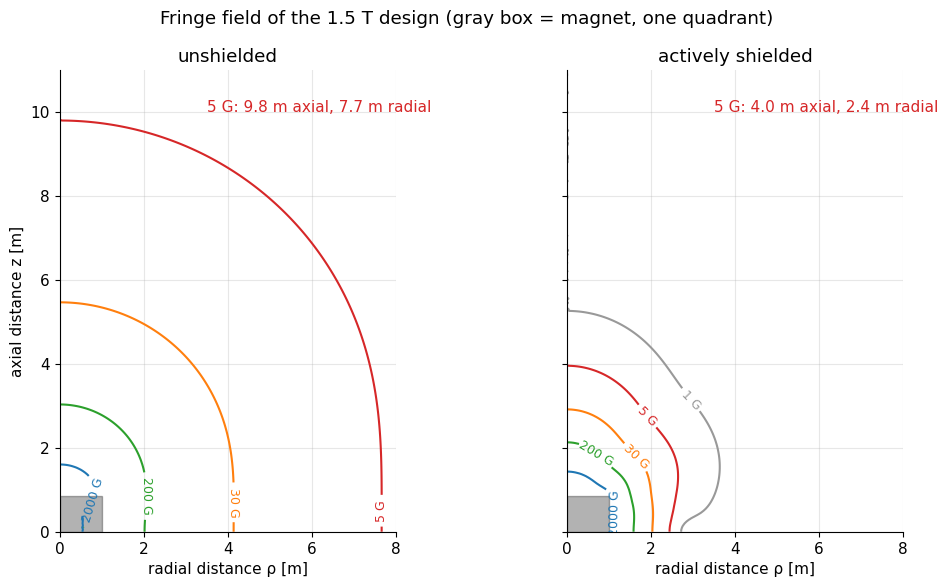

In [17]:
coils_sh = design_magnet(z_pos, 0.5, B0_design, extra=(0.65, 0.9))
for zk, rk, NIk in coils_sh:
    print(f"pair at z = +-{zk:4.2f} m, R = {rk} m: NI = {NIk/1e3:7.1f} kA-turns")
_, b = magnet_field(0.25 * np.sin(th), 0.25 * np.cos(th), coils_sh)
_, Bc_sh = magnet_field(0.0, 0.0, coils_sh)
print(f"shielded design: {np.ptp(b)/Bc_sh*1e6:.1f} ppm pk-pk over 50 cm DSV; "
      f"stored energy {stored_energy(coils_sh)/1e6:.1f} MJ (unshielded {stored_energy(coils_unsh)/1e6:.1f} MJ)")

# fringe-field maps in the (rho, z) half plane
rr = np.linspace(0.0, 8.0, 161); zz = np.linspace(0.0, 11.0, 221)
RR, ZZ = np.meshgrid(rr, zz)
fig, ax = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
fivegauss = {}
for a_, (name, cs_) in zip(ax, [("unshielded", coils_unsh), ("actively shielded", coils_sh)]):
    Br, Bz = magnet_field(RR, ZZ, cs_)
    Bm = np.hypot(Br, Bz) * 1e3                           # [mT]
    c = a_.contour(RR, ZZ, Bm, levels=[0.1, 0.5, 3.0, 20.0, 200.0], colors=["0.6", "C3", "C1", "C2", "C0"])
    a_.clabel(c, fmt={0.1: "1 G", 0.5: "5 G", 3.0: "30 G", 20.0: "200 G", 200.0: "2000 G"}, fontsize=9)
    a_.add_patch(plt.Rectangle((0, 0), 1.0, 0.85, color="k", alpha=0.3))
    a_.set_aspect("equal"); a_.set_xlabel("radial distance ρ [m]"); a_.set_title(name)
    # 5 G extent along the axis and radially
    Br_ax, Bz_ax = magnet_field(1e-6, zz, cs_); Br_r, Bz_r = magnet_field(rr, 0.0, cs_)
    z5 = zz[np.where(np.hypot(Br_ax, Bz_ax) > 0.5e-3)[0].max()]
    r5 = rr[np.where(np.hypot(Br_r, Bz_r) > 0.5e-3)[0].max()]
    fivegauss[name] = (z5, r5)
    a_.text(3.5, 10, f"5 G: {z5:.1f} m axial, {r5:.1f} m radial", color="C3")
ax[0].set_ylabel("axial distance z [m]")
plt.suptitle("Fringe field of the 1.5 T design (gray box = magnet, one quadrant)")
plt.show()

*Interpretation:* the shield coil shrinks the 5-gauss zone from ~10 m × 7.5 m to ~4 m × 2.5 m — the typical footprint quoted in vendor siting manuals for actively shielded 1.5 T magnets. The price: about 30 % more ampere-turns on the main coils, a shield coil, and roughly twice the stored energy. Very large magnets (e.g. some 7 T and above) add or rely on **passive shielding**: hundreds of tonnes of steel in the walls of the magnet room.

> **🔧 Engineering reality — siting:** the site plan must consider: the 5 G line (controlled access, no pacemaker patients, signage); ferromagnetic masses that move (elevators, cars, trucks within a few metres distort $B_0$ — moving steel is a common cause of image artifacts); floor loading (4–12 t on a small footprint); vibration from nearby traffic or machinery; the Faraday cage; the quench-pipe route to the outside; chilled water and power; and transport access for delivering (and someday removing) the magnet.

## 10. Forces on ferromagnetic objects

A magnetic moment $\vec m$ in a field gradient feels a translational force $\vec F=\nabla(\vec m\cdot\vec B)$; along the axis $F_z = m\,dB/dz$. For a soft-iron object the moment itself is induced by the field:

* **below saturation**, a sphere of iron has magnetization $M=3B/\mu_0$ (the factor 3 comes from its demagnetizing field), so $F_z = \frac{3V}{\mu_0}\,B\,\frac{dB}{dz}$ — the force grows with the **product** $B\,dB/dz$ (unit T²/m);
* **above saturation** ($M=M_s$), $F_z = M_sV\,\frac{dB}{dz}$ — it grows only with the gradient.

Comparing with the object's weight $\rho_{Fe}Vg$ shows that the ratio is **independent of the object's size**: a paperclip and an oxygen cylinder are accelerated alike.

unshielded: max |B dB/dz| =  2.4 T^2/m at z = 0.92 m; max |dB/dz| =  2.2 T/m; max force/weight =   48
shielded  : max |B dB/dz| =  2.6 T^2/m at z = 0.91 m; max |dB/dz| =  2.5 T/m; max force/weight =   55


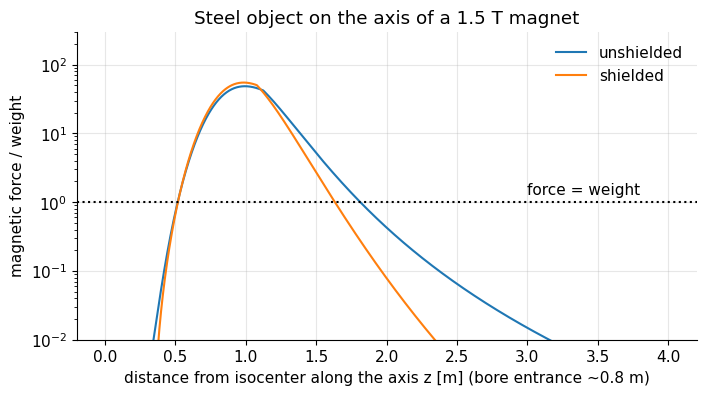

In [18]:
rho_Fe, g_acc, Ms = 7870.0, 9.81, 1.7e6
zz = np.linspace(0, 4.0, 2001)
for name, cs_ in [("unshielded", coils_unsh), ("shielded", coils_sh)]:
    _, Bz_ax = magnet_field(1e-6, zz, cs_)               # on-axis field [T]
    dBdz = np.gradient(Bz_ax, zz)
    M = np.minimum(3 * np.abs(Bz_ax) / mt.MU0, Ms)       # induced magnetization of an iron sphere [A/m]
    ratio = M * np.abs(dBdz) / (rho_Fe * g_acc)          # magnetic force / weight
    i = np.argmax(np.abs(Bz_ax * dBdz))
    print(f"{name:10s}: max |B dB/dz| = {np.abs(Bz_ax*dBdz).max():4.1f} T^2/m at z = {zz[i]:.2f} m; "
          f"max |dB/dz| = {np.abs(dBdz).max():4.1f} T/m; max force/weight = {ratio.max():4.0f}")
    plt.plot(zz, ratio, label=name)
plt.axhline(1, color="k", ls=":"); plt.text(3.0, 1.3, "force = weight")
plt.yscale("log"); plt.ylim(0.01, 300)
plt.xlabel("distance from isocenter along the axis z [m] (bore entrance ~0.8 m)")
plt.ylabel("magnetic force / weight")
plt.title("Steel object on the axis of a 1.5 T magnet"); plt.legend(); plt.show()

*Interpretation:* well outside the magnet the force is negligible, but within roughly a metre of the bore entrance it rises within a few tens of centimetres to **tens of times the object's weight** — the projectile effect. Shielded magnets have *steeper* fringe fields, so the danger zone is smaller but the increase is more sudden. Inside the bore center ($dB/dz\approx0$) there is no net force, but there is still a **torque** that tries to align elongated objects with $B_0$. Implant labels therefore specify a maximum **spatial field gradient** (T/m) and sometimes $B\,dB/dz$ (T²/m); vendors publish fringe-field maps for this purpose. → [B6](B6_MRI_Safety.ipynb)

## 11. Field strength trade-offs

| Effect | Scaling with $B_0$ | Consequence |
|---|---|---|
| Polarization $M_0$ | $\propto B_0$ | more signal |
| Induced voltage | $\propto B_0^2$ ($M_0$ × $\omega_0$) | |
| Noise (body-dominated) | $\propto B_0$ | |
| **SNR** | $\approx\propto B_0$ (measured in brain between 3 and 9.4 T: closer to $B_0^{1.5\text{–}1.7}$) | resolution, speed |
| $T_1$ | lengthens, roughly $\propto B_0^{0.3\text{–}0.4}$ in tissue | longer TR needed, lower T1 contrast for some tissues, better for ASL/TOF |
| $T_2$, $T_2^*$ | $T_2$ slightly shorter; $T_2^*$ much shorter (susceptibility) | |
| Chemical shift (Hz) | $\propto B_0$ | better spectroscopy & fat suppression; larger fat–water displacement artifacts |
| Susceptibility effects (Hz) | $\propto B_0$ | more BOLD/SWI contrast; more distortion and dropout |
| **SAR** (same pulse, same flip angle) | $\propto B_0^2$ | limits fast spin-echo, bSSFP at 3 T and above |
| RF wavelength in tissue | $\propto 1/B_0$ | $B_1^+$ inhomogeneity at ≥ 3 T (body) and 7 T (head) |
| Magnet cost, weight, stored energy, fringe field | grows strongly ($E\propto B_0^2$ for fixed geometry) | cost, siting |

In [19]:
fields = np.array([0.55, 1.5, 3.0, 7.0])
eps_r = np.array([110.0, 72.0, 63.0, 58.0])         # approx. relative permittivity of muscle at f0 (Gabriel-type data)
T1_gm_3T = 1.6                                       # gray-matter T1 at 3 T [s] (approx.)
print(f"{'B0 [T]':>7} {'f0 [MHz]':>9} {'SNR rel.':>9} {'fat-water [Hz]':>15} {'9.4 ppm air/tissue [Hz]':>24} "
      f"{'SAR rel.':>9} {'lambda tissue [cm]':>19} {'T1 GM ~[s]':>11}")
for B0, er in zip(fields, eps_r):
    f0 = mt.larmor_frequency(B0)
    print(f"{B0:7.2f} {f0/1e6:9.1f} {B0/1.5:9.2f} {abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)):15.0f} "
          f"{mt.ppm_to_hz(9.4, B0):24.0f} {(B0/1.5)**2:9.2f} {2.998e8/(f0*np.sqrt(er))*100:19.1f} "
          f"{T1_gm_3T*(B0/3.0)**0.35:11.2f}")

 B0 [T]  f0 [MHz]  SNR rel.  fat-water [Hz]  9.4 ppm air/tissue [Hz]  SAR rel.  lambda tissue [cm]  T1 GM ~[s]
   0.55      23.4      0.37              82                      220      0.13               122.1        0.88
   1.50      63.9      1.00             224                      600      1.00                55.3        1.26
   3.00     127.7      2.00             447                     1201      4.00                29.6        1.60
   7.00     298.0      4.67            1043                     2802     21.78                13.2        2.15


*Interpretation:* going from 1.5 T to 3 T doubles SNR and chemical-shift dispersion but quadruples SAR and halves the RF wavelength in tissue to ~30 cm (about the width of the abdomen → visible $B_1^+$ shading in body imaging). At 7 T the wavelength (~12 cm) is smaller than the head, producing a bright center and dark temporal lobes unless parallel transmission or dielectric pads are used ([B5](B5_RF_System_and_Receive_Chain.ipynb)). At 0.55 T SAR and susceptibility artifacts are ~7× and ~3× smaller than at 1.5 T — attractive near metal implants and in the lungs — at the price of SNR. ($T_1$ values here follow a rough power law and are only indicative.)

## 12. Trends: low field and helium-free magnets

* **High-performance low field (0.5–1 T):** modern gradients, many-channel receive arrays and deep-learning reconstruction recover much of the lost SNR. Benefits: lower cost and siting effort, wider bores (80 cm), less SAR and susceptibility artifact, safer with many implants, interventional use. Example: 0.55 T systems with < 1 L of helium.
* **Very low field, portable (≤ 0.1 T):** permanent-magnet scanners that roll to the bedside (e.g. 64 mT for ICU brain imaging), running from a standard power outlet with little or no RF shielding (active electromagnetic-interference cancellation using extra sensor coils).
* **Helium-free / sealed superconducting magnets:** conduction cooling by cryocoolers, small sealed helium inventories (≈1–10 L), MgB₂ and HTS conductors operating at 10–20 K where cryocoolers are far more efficient. They remove the quench pipe and helium refills from the siting requirements.
* **Ultra-high field (7–11.7 T and beyond):** for research and selected clinical neuro/MSK uses, with NbTi at 1.8 K or Nb₃Sn, hundreds of MJ stored energy, and extensive passive shielding.

> **🧭 Intuition:** the field strength of a scanner is a product decision balancing physics (SNR ∝ $B_0$) against engineering (energy ∝ $B_0^2$, SAR ∝ $B_0^2$, wavelength ∝ $1/B_0$) and economics (helium, siting, cost). Better reconstruction and receive hardware shift the optimum — currently in *both* directions.

## Key takeaways

* Whole-body fields above ~0.5 T need **superconducting** magnets: a resistive 1.5 T solenoid would dissipate ~1 MW, and permanent magnets drift ~1200 ppm/K.
* Clinical magnets use **NbTi at 4.2 K** in a copper matrix, millions of ampere-turns, tens of km of wire, and run in **persistent mode** with < 1 nΩ residual resistance (drift < 0.1 ppm/h).
* Stored energy is MJ-scale ($\tfrac12LI_c^2$, ∝ $B_0^2$): ~3–5 MJ at 1.5 T, ~10–15 MJ at 3 T; it is all released in a **quench**, which can boil off most of the ~1500 L of helium (→ ~1000 m³ of gas): quench pipe and O₂ monitoring are essential.
* 1 W of heat leak boils ~1.4 L/h of LHe; cryocoolers give zero boil-off; **sealed low-helium** magnets need < 10 L.
* Homogeneity is specified in **ppm over a DSV**; the field error is expanded in **spherical harmonics**. Multi-coil designs cancel low orders; **passive** (steel) and **active** (coil) shims remove the rest; patient susceptibility leaves local errors that low-order shims cannot fix.
* **Active shielding** (reverse coils cancelling the dipole moment) shrinks the 5-gauss line from ~10 m to ~4 m for 1.5 T.
* Forces on iron scale with $B\,dB/dz$ (unsaturated) or $dB/dz$ (saturated) and can exceed the object's weight by 10–100× near the bore entrance, independent of the object's size.
* Higher $B_0$: more SNR, longer $T_1$, more chemical-shift and susceptibility effects, SAR ∝ $B_0^2$, shorter RF wavelength (B1 inhomogeneity); low-field and helium-free magnets are a strong current trend.

## Check your understanding

1. Estimate the stored energy of a 3 T magnet whose field fills a cylinder of 1 m diameter and 1.6 m length (ignore the field outside). If it operates at 400 A, what is its inductance?

<details><summary>Answer</summary>

$E\approx\frac{B_0^2}{2\mu_0}V=\frac{9}{2\cdot4\pi\times10^{-7}}\cdot\pi(0.5)^2(1.6)\approx3.6\times10^6\cdot1.26\approx4.5$ MJ (real magnets store 2–3× more because of the field in and around the windings and the shield coils). $L=2E/I_c^2=2\cdot4.5\times10^6/400^2\approx56$ H.

</details>

2. A magnet's cold head fails. The heat leak into the helium bath is 0.6 W and 1200 L of LHe remain. How long until the helium is gone (ignoring that the magnet would need service well before that)?

<details><summary>Answer</summary>

One litre needs $125\times10^{-3}\cdot20.9\times10^3\approx2.6$ kJ. $0.6$ W evaporates $0.6\cdot3600/2600\approx0.83$ L/h ≈ 20 L/day, so ~60 days. In practice, the magnet must not run below a minimum level (the coil must stay covered), so the real margin is shorter.

</details>

3. Why can low-order active shimming not remove the field error near the frontal sinuses?

<details><summary>Answer</summary>

The air–tissue susceptibility difference creates a dipole-like field that varies on the centimetre scale (∝ $1/d^3$). Representing such a localized pattern requires very high-order spherical harmonics; shim coils provide only orders 1–2 (sometimes 3), which describe smooth, large-scale variations. The local residual of several ppm causes dropout and distortion.

</details>

4. Why does a steel paperclip experience about the same acceleration towards the magnet as a steel gas cylinder?

<details><summary>Answer</summary>

Both the magnetic force and the weight are proportional to the volume of steel: $F = M V\,dB/dz$ (with $M=3B/\mu_0$ or $M_s$) and $W=\rho_{Fe}Vg$. The ratio $F/W$ depends only on the field, its gradient and the material — not on size (shape modifies the factor 3 somewhat).

</details>

5. What does active shielding do to the stored energy and why?

<details><summary>Answer</summary>

It increases it (roughly doubles in our design). The shield coil's reversed field partly cancels the field inside the bore, so the main coils need more ampere-turns to reach the same $B_0$; in addition the shield coil itself stores energy in the region between the coils, where the fields of the two coil sets are strong.

</details>

6. A 0.3 T permanent-magnet scanner's magnet warms by 0.05 K during the day. How much does its Larmor frequency drift?

<details><summary>Answer</summary>

$f_0=12.77$ MHz; NdFeB loses ~0.12 %/K, so $\Delta f=0.0012\cdot0.05\cdot12.77\times10^6\approx770$ Hz (60 ppm) — several pixels of shift unless tracked.

</details>

---
*New chapter written for this adaptation; see references below. Helper functions defined here that are not (yet) in `mri_tools`: `loop_field_exact` (elliptic-integral loop field), `magnet_field`, `design_magnet`, `mutual_inductance`, `stored_energy`, `sph_basis` (real solid spherical harmonics), `dipole_bz_ppm`.*

**References**
* D. W. McRobbie, E. A. Moore, M. J. Graves, M. R. Prince, *MRI from Picture to Proton*, 3rd ed., Cambridge University Press, 2017 (chapters on magnets, shimming and safety).
* R. W. Brown, Y.-C. N. Cheng, E. M. Haacke, M. R. Thompson, R. Venkatesan, *Magnetic Resonance Imaging: Physical Principles and Sequence Design*, 2nd ed., Wiley, 2014.
* M. N. Wilson, *Superconducting Magnets*, Oxford University Press, 1983.
* Y. Lvovsky, E. W. Stautner, T. Zhang, "Novel technologies and configurations of superconducting magnets for MRI", *Superconductor Science and Technology* 26, 093001 (2013).
* A. E. Campbell-Washburn et al., "Opportunities in interventional and diagnostic imaging by using high-performance low-field-strength MRI", *Radiology* 293, 384–393 (2019).
* IEC 60601-2-33, *Medical electrical equipment – Part 2-33: Particular requirements for the basic safety and essential performance of magnetic resonance equipment for medical diagnosis*.